# 02 — Comprensión general del dataset

## Propósito

Conocer el **tamaño**, la **composición** y el **impacto económico inicial** del fraude.

Respondemos las preguntas del README — sección 2:

1. ¿Cuántas transacciones hay y qué porcentaje son fraudulentas?
2. ¿Cuál es el monto total transaccionado y cuánto corresponde a fraude?
3. ¿Cuál es el ticket promedio normal vs fraudulento?

In [ ]:
from pathlib import Path

# Rutas del proyecto (ejecutar notebooks desde la carpeta notebooks/)
PROJECT_ROOT = Path('..').resolve()
DATA_RAW = PROJECT_ROOT / 'data' / 'raw' / 'paysim.csv' #donde se encuentra el dataset
IMAGES_DIR = PROJECT_ROOT / 'images' #donde se guardan las imagenes
REPORTS_DIR = PROJECT_ROOT / 'reports' #donde se guardan los reportes

IMAGES_DIR.mkdir(parents=True, exist_ok=True) #crea la carpeta si no existe
REPORTS_DIR.mkdir(parents=True, exist_ok=True) #crea la carpeta si no existe

USE_SAMPLE = False
SAMPLE_FRAC = 0.05  # 5% estratificado por fraude si USE_SAMPLE es True
RANDOM_STATE = 42


In [ ]:
import pandas as pd #para la manipulacion de datos
import numpy as np #para la manipulacion de datos
import matplotlib.pyplot as plt #para la visualizacion de datos
import seaborn as sns #para la visualizacion de datos

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

if not DATA_RAW.exists(): #si el dataset no existe
    raise FileNotFoundError(
        f'No encontré el dataset en {DATA_RAW}. '
        'Verifica el enlace simbólico data/raw/paysim.csv' #entonces arroja un error
    ) 

# Tipos optimizados para ahorrar memoria. esto lo haceemos para definir el tipo de datos de cada columna
dtype_map = {
    'type': 'category',
    'nameOrig': 'string',
    'nameDest': 'string',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8',
}

print('Cargando datos... (puede tardar unos minutos)')
df = pd.read_csv(DATA_RAW, dtype=dtype_map) #cargar el dataset

if USE_SAMPLE:
    # Muestra estratificada: conserva la proporción de fraude del dataset completo
    fraud = df[df['isFraud'] == 1]
    legit = df[df['isFraud'] == 0]
    n_fraud = max(1, int(len(fraud) * SAMPLE_FRAC))
    n_legit = int(len(legit) * SAMPLE_FRAC)
    df = pd.concat([
        fraud.sample(n=min(n_fraud, len(fraud)), random_state=RANDOM_STATE),
        legit.sample(n=min(n_legit, len(legit)), random_state=RANDOM_STATE),
    ]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f'Modo muestra activado: {len(df):,} filas')

print(f'Filas: {len(df):,} | Columnas: {df.shape[1]}')
df.head()


Cargando datos... (puede tardar unos minutos)
Filas: 6,362,620 | Columnas: 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## Primer vistazo: estructura y calidad básica

Primero verifico qué cargué: reviso tipos de datos, valores nulos y filas duplicadas. Así sé si puedo interpretar los indicadores directamente o si antes tendría que limpiar problemas básicos del dataset.

In [3]:
df.info()
print('\n--- Valores nulos por columna ---')
print(df.isna().sum())
print('\n--- Duplicados exactos ---')
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int64   
 1   type            category
 2   amount          float64 
 3   nameOrig        string  
 4   oldbalanceOrg   float64 
 5   newbalanceOrig  float64 
 6   nameDest        string  
 7   oldbalanceDest  float64 
 8   newbalanceDest  float64 
 9   isFraud         int8    
 10  isFlaggedFraud  int8    
dtypes: category(1), float64(5), int64(1), int8(2), string(2)
memory usage: 406.5 MB

--- Valores nulos por columna ---
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

--- Duplicados exactos ---
0


## Tipos de transacción presentes

Ahora observo las categorías de operación y cuántas filas aporta cada una. Todavía no estoy diciendo cuál es riesgosa; esa comparación con `isFraud` la haré en el notebook 04.

In [4]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

## KPIs generales de fraude

En esta sección construimos las **métricas de negocio** que un equipo de riesgos o fraude suele pedir en la primera reunión con datos. No usamos modelos todavía: solo **describimos** qué tan grande es el problema en volumen y en dinero.

Dividimos el análisis en cuatro pasos:

| Paso | Qué medimos | Para qué sirve |
|------|-------------|----------------|
| 1 | Cantidad de transacciones y tasa de fraude | Saber qué tan **raro** es el fraude (desbalance de clases) |
| 2 | Montos totales y participación del fraude | Saber el **impacto económico** aunque haya pocos casos |
| 3 | Ticket promedio y mediano | Comparar el **tamaño típico** de operaciones legítimas vs fraudulentas |
| 4 | Tabla resumen (`kpis`) | Tener un solo objeto reutilizable en gráficos e insights más abajo |

En cada celda de código verás pocas líneas a propósito: así es más fácil seguir qué variable guarda qué idea de negocio.

### Paso 1 — Volumen: ¿cuántas transacciones hay y cuántas son fraude?

Aquí contamos **filas** del DataFrame, no dinero todavía.

| Código | Función / método | Qué hace en este contexto |
|--------|------------------|---------------------------|
| `len(df)` | Función built-in de Python | Devuelve el número de filas = **total de transacciones** en el dataset cargado. |
| `df['isFraud']` | Acceso a columna (Serie de pandas) | Columna objetivo: `0` = legítima, `1` = fraudulenta. |
| `.sum()` | Suma de la Serie | Sobre ceros y unos, equivale a **contar** cuántas filas tienen `isFraud == 1`. |
| `int(...)` | Conversión a entero | Dejamos el conteo como número entero legible (sin decimales). |
| `fraud_tx / total_tx` | División | **Tasa de fraude** en proporción (0 a 1); luego la multiplicamos por 100 para el porcentaje. |

**Qué estás haciendo:** respondes la pregunta del README *«¿cuántas transacciones hay y qué porcentaje son fraudulentas?»* antes de mirar montos.

In [5]:
total_tx = len(df)
fraud_tx = int(df['isFraud'].sum()) #suma de los valores de la columna isFraud
fraud_rate = fraud_tx / total_tx #tasa de fraude

print(f'Total transacciones: {total_tx:,}')
print(f'Transacciones fraudulentas: {fraud_tx:,}')
print(f'Tasa de fraude: {fraud_rate * 100:.4f}%')

Total transacciones: 6,362,620
Transacciones fraudulentas: 8,213
Tasa de fraude: 0.1291%


Al ejecutar este conteo observo que las transacciones fraudulentas representan aproximadamente **0,13%** del total. Es decir, el fraude es poco frecuente en número de operaciones, pero aun así existen **8.213 casos reales** que el análisis no puede ignorar.


### Paso 2 — Impacto económico: montos totales y cuánto es fraude

Ahora sumamos la columna `amount` (monto de cada transacción).

| Código | Función / método | Qué hace en este contexto |
|--------|------------------|---------------------------|
| `df['amount'].sum()` | Suma de toda la columna | **Monto total** movido en todas las transacciones (legítimas + fraudulentas). |
| `df.loc[condición, 'amount']` | Filtrado por etiqueta + columna | `.loc` selecciona filas donde `isFraud == 1` y solo la columna `amount`; luego `.sum()` agrega esos montos. |
| `fraud_amount / total_amount` | División | **Participación del fraude en el dinero**: qué fracción del volumen monetario total corresponde a operaciones fraudulentas. |

**Qué estás haciendo:** respondes *«¿cuál es el monto total transaccionado y cuánto corresponde a fraude?»* Un fraude raro en cantidad de casos puede ser grave si concentra mucho dinero.

In [ ]:
total_amount = df['amount'].sum() #suma de los montos de todas las transacciones
fraud_amount = df.loc[df['isFraud'] == 1, 'amount'].sum() #suma de los montos de las transacciones fraudulentas
fraud_amount_share = fraud_amount / total_amount #participacion del fraude en el monto total

print(f'Monto total transaccionado: {total_amount:,.2f}')
print(f'Monto total fraudulento: {fraud_amount:,.2f}')
print(f'Participación del fraude en el monto: {fraud_amount_share * 100:.4f}%')

Monto total transaccionado: 1,144,392,944,759.77
Monto total fraudulento: 12,056,415,427.84
Participación del fraude en el monto: 1.0535%


Aunque los fraudes son pocos, el monto fraudulento acumulado es alto y representa aproximadamente **1,05%** de todo el dinero transaccionado. Esto me indica que no basta con optimizar por cantidad de alertas: también necesito prestar atención a operaciones de alto valor y comprobar después si el monto, junto con el comportamiento habitual del usuario, sirve como señal de riesgo.

### Paso 3 — Tickets: tamaño típico de cada operación

Separamos el DataFrame en dos subconjuntos para comparar **montos por transacción**, no totales acumulados.

| Código | Función / método | Qué hace en este contexto |
|--------|------------------|---------------------------|
| `df[df['isFraud'] == 0]` | Filtrado booleano | Crea `legit`: solo transacciones **no fraudulentas**. |
| `df[df['isFraud'] == 1]` | Filtrado booleano | Crea `fraud`: solo transacciones **fraudulentas**. |
| `.mean()` | Promedio | **Ticket promedio**: suma de montos / cantidad de filas en ese grupo. Sensible a valores extremos (outliers). |
| `.median()` | Mediana | Valor central del 50 %; en fraude suele ser más estable que la media si hay pocos casos muy grandes. |

**Qué estoy haciendo:** respondo *«¿cuál es el ticket promedio normal vs fraudulento?»*. Si el promedio de fraude es mucho mayor que el de operaciones legítimas, el riesgo puede estar ligado a montos altos.

In [12]:
legit = df[df['isFraud'] == 0] #es la tabla donde se encuentran las transacciones no fraudulentas
fraud = df[df['isFraud'] == 1] #es la tabla donde se encuentran las transacciones fraudulentas

avg_ticket_legit = legit['amount'].mean()
avg_ticket_fraud = fraud['amount'].mean()
median_ticket_fraud = fraud['amount'].median()

print(f'Ticket promedio (no fraude): {avg_ticket_legit:,.2f}')
print(f'Ticket promedio (fraude): {avg_ticket_fraud:,.2f}')
print(f'Ticket mediano (fraude): {median_ticket_fraud:,.2f}')

Ticket promedio (no fraude): 178,197.04
Ticket promedio (fraude): 1,467,967.30
Ticket mediano (fraude): 441,423.44



El ticket promedio de fraude (**~1.467.967**) es mucho mayor que el de operaciones legítimas (**~178.197**), casi **8 veces**. Tiene sentido: quien defrauda suele buscar sacar el máximo por operación. La variable `amount` será clave en el análisis y en el modelo.

### Paso 4 — Tabla resumen de KPIs

Unimos todas las métricas que hemos obtenido en un objeto **`pd.Series`**: una columna con nombre de indicador → valor. Así se puede reutilizar `kpis['Tasa de fraude (%)']` en celdas de insight y reportes sin repetir cálculos.

| Código | Función / método | Qué hace en este contexto |
|--------|------------------|---------------------------|
| `pd.Series({...})` | Constructor de pandas | Crea la tabla de KPIs a partir de un diccionario clave–valor. |
| `round(x * 100, 4)` | Redondeo | Pasa proporciones (0–1) a **porcentaje** con 4 decimales para lectura. |
| Dejar `kpis` al final de la celda | Display en Jupyter | Muestra la Serie completa como tabla en el notebook. |

**Qué estoy haciendo:** consolido los pasos 1–3 en un único artefacto reutilizable para gráficos y conclusiones.

In [8]:
kpis = pd.Series({
    'Total transacciones': total_tx,
    'Total fraudes': fraud_tx,
    'Tasa de fraude (%)': round(fraud_rate * 100, 4),
    'Monto total transaccionado': total_amount,
    'Monto total fraudulento': fraud_amount,
    'Participación monto fraude (%)': round(fraud_amount_share * 100, 4),
    'Ticket promedio (no fraude)': avg_ticket_legit,
    'Ticket promedio (fraude)': avg_ticket_fraud,
    'Ticket mediano (fraude)': median_ticket_fraud,
})

kpis

Total transacciones               6.362620e+06
Total fraudes                     8.213000e+03
Tasa de fraude (%)                1.291000e-01
Monto total transaccionado        1.144393e+12
Monto total fraudulento           1.205642e+10
Participación monto fraude (%)    1.053500e+00
Ticket promedio (no fraude)       1.781970e+05
Ticket promedio (fraude)          1.467967e+06
Ticket mediano (fraude)           4.414234e+05
dtype: float64

### Cómo leer estos números

- **Tasa de fraude baja** es normal: hay muchas transacciones legítimas y pocas fraudulentas (*desbalance de clases*).
- Si el **monto fraudulento** o su participación es relevante, el riesgo económico puede ser alto aunque haya pocos casos.
- Comparar **ticket promedio** ayuda a ver si el fraude se asocia a operaciones de mayor valor.

## Visualización: distribución del fraude (conteo)

Complementamos los KPIs con **gráficos** para comunicar el desbalance de clases: casi todas las transacciones son legítimas y una fracción mínima es fraude.

Usamos dos vistas del **mismo conteo**:

1. **Barras** — comparar magnitudes absolutas (cuántas filas hay en cada clase).
2. **Pastel** — ver la proporción porcentual de cada clase sobre el total.

El archivo se guarda en `images/fraud_distribution.png` para el informe o el README.

### Preparar los conteos para graficar

Antes de dibujar, agrupamos cuántas filas hay por valor de `isFraud`.

| Código | Función / método | Qué hace en este contexto |
|--------|------------------|---------------------------|
| `.value_counts()` | Conteo por categoría | Cuenta filas para `0` y `1` automáticamente. |
| `.sort_index()` | Ordenar índice | Deja primero `0` (no fraude) y luego `1` (fraude) para etiquetas consistentes en los ejes. |

In [9]:
counts = df['isFraud'].value_counts().sort_index()
counts

isFraud
0    6354407
1       8213
Name: count, dtype: int64

### Generar y guardar la figura

| Código | Función / método | Qué hace en este contexto |
|--------|------------------|---------------------------|
| `plt.subplots(1, 2, ...)` | Matplotlib | Crea **dos subgráficos** en una fila: barras a la izquierda, pastel a la derecha. |
| `ax[0].bar(...)` | Gráfico de barras | Altura de cada barra = `counts.values` (número de transacciones). |
| `ax[1].pie(..., autopct=...)` | Gráfico circular | `autopct` imprime el **porcentaje** en cada porción del pastel. |
| `plt.tight_layout()` | Ajuste de diseño | Evita que títulos o etiquetas se corten. |
| `plt.savefig(out, ...)` | Guardar imagen | Escribe el PNG en la carpeta `images/` del proyecto. |
| `plt.show()` | Mostrar en notebook | Renderiza la figura en Cursor/Jupyter. |

**Qué estoy haciendo:** traduzco la tasa de fraude de números a una imagen que cualquier persona interesada en el análisis puede entender de un vistazo.

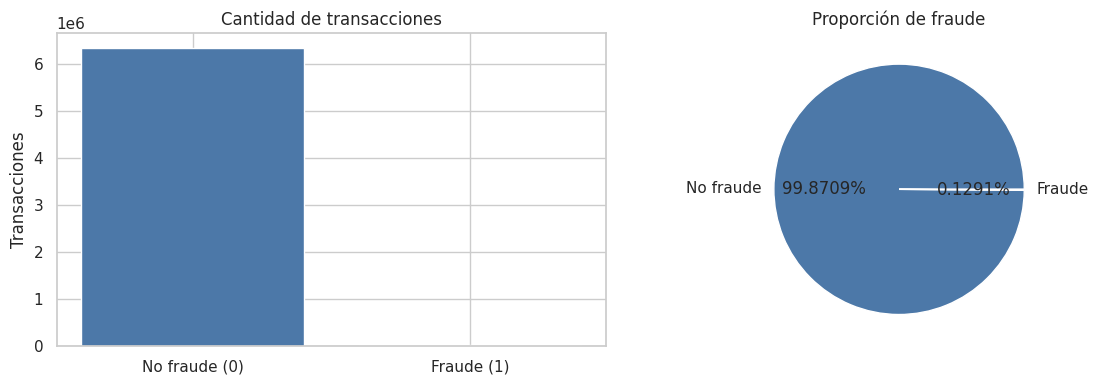

Gráfico guardado en /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/fraud_distribution.png


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(['No fraude (0)', 'Fraude (1)'], counts.values, color=['#4c78a8', '#e45756'])
ax[0].set_title('Cantidad de transacciones')
ax[0].set_ylabel('Transacciones')

ax[1].pie(
    counts.values,
    labels=['No fraude', 'Fraude'],
    autopct='%1.4f%%',
    colors=['#4c78a8', '#e45756'],
)
ax[1].set_title('Proporción de fraude')

plt.tight_layout()
out = IMAGES_DIR / 'fraud_distribution.png'
plt.savefig(out, bbox_inches='tight')
plt.show()
print('Gráfico guardado en', out)

## Conclusión general del notebook

PaySim muestra un patrón típico de fraude financiero: **pocos casos, mucho impacto**. En volumen el fraude es del **0,13%**, pero concentra **1,05%** del dinero y tickets mucho más altos que las operaciones normales.

Para el negocio, el riesgo no está en la cantidad de transacciones fraudulentas sino en **detectar a tiempo** esas pocas que mueven montos grandes. El siguiente paso es profundizar por tipo de operación y variables de saldo en el notebook 04.

## Siguiente paso

Abre `04_exploratory_data_analysis.ipynb` para profundizar por **tipo de operación**,
**rangos de monto**, **saldos** y **efectividad de alertas** (`isFlaggedFraud`).